<a href="https://colab.research.google.com/github/danielaceves5162/Tareas_TS_Aceves_Daniel/blob/main/HW3_Aceves_Daniel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TAREA 3: análisis de relaciones entre variables del OOIP

Aceves Maya Christopher Daniel

Temas selectos

fecha de entrega 17 de septiembre de 2026

DR. MOISES VELASCO LOZANO

1. Introducción

El objetivo de la tarea es aplicar los métodos de covarianza por pares, coeficiente de correlación por pares y coeficiente de correlación por rangos a
los datos contenidos en el archivo OOIP.csv, con el propósito de identificar y ordenar las propiedades del
yacimiento de acuerdo con su grado de asociación con el volumen original de aceite, N (MMSTB).

2. Desarrollo

Como primera parte del desarrollo vamos a importar las librerías, cargamos los datos y definimos variables; área, espesor, porosidad, saturación de aceite SO, y el factor volumétrico del aceite BO

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
%matplotlib inline

# Cargar datos
url = "https://raw.githubusercontent.com/Moises13r/PetroleumEng/main/Special%20Topics/Data/OOIP.csv"
df = pd.read_csv(url)
print(df.head())

# Definir variables
Y = df['N (MMSTB)'].values
X = {
    'Area': df['Area (acres)'].values,
    'Thickness': df['Thickness h (ft)'].values,
    'Porosity': df['Porosity'].values,
    'So': df['Oil Saturation So'].values,
    'Bo': df['Oil FVF Bo (rb/STB)'].values}

   Sample  Area (acres)  Thickness h (ft)  Porosity  Oil Saturation So  \
0       1        1051.9              10.8     0.141              0.539   
1       2        1108.6             107.9     0.099              0.619   
2       3         412.3              64.6     0.086              0.530   
3       4         908.3              32.7     0.210              0.774   
4       5        1304.8              86.2     0.155              0.512   

   Oil FVF Bo (rb/STB)  N (MMSTB)  Grouped Feature  
0                1.418      4.724           608.88  
1                1.065     53.398          6882.92  
2                1.375      6.850           882.91  
3                1.053     35.568          4584.68  
4                1.529     45.289          5837.75  


2.1 desarrollo

Para la siguiente parte vamos a realizar los cálculos con el método de la covarianza por pares, correlación por pares y correlación por rangos


 COVARIANZA POR PARES CON N:
Propiedad   Covarianza
     Area 11614.215599
Thickness   661.837836
 Porosity     0.691458
       So     0.273025
       Bo    -0.728360


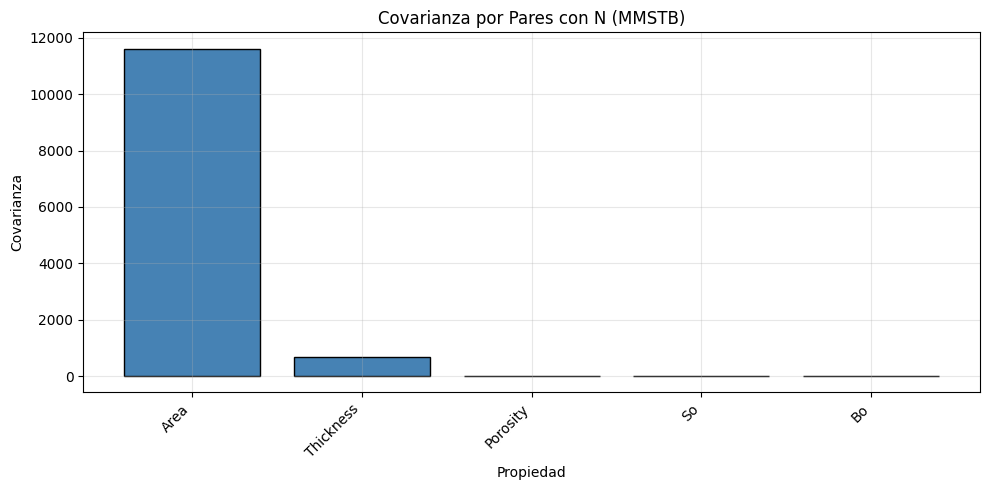


 CORRELACIÓN POR PARES CON N:
Propiedad  Correlación por pares
     Area               0.696850
Thickness               0.531701
 Porosity               0.330148
       So               0.061324
       Bo              -0.125944


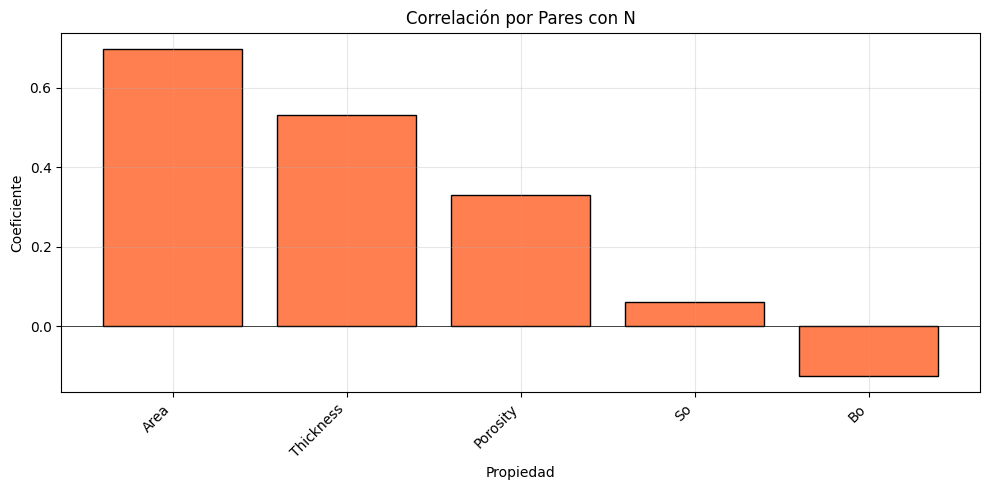


 CORRELACIÓN POR RANGOS CON N:
Propiedad  Correlación por rangos
     Area                0.669916
Thickness                0.643024
 Porosity                0.317453
       So                0.024017
       Bo               -0.125672


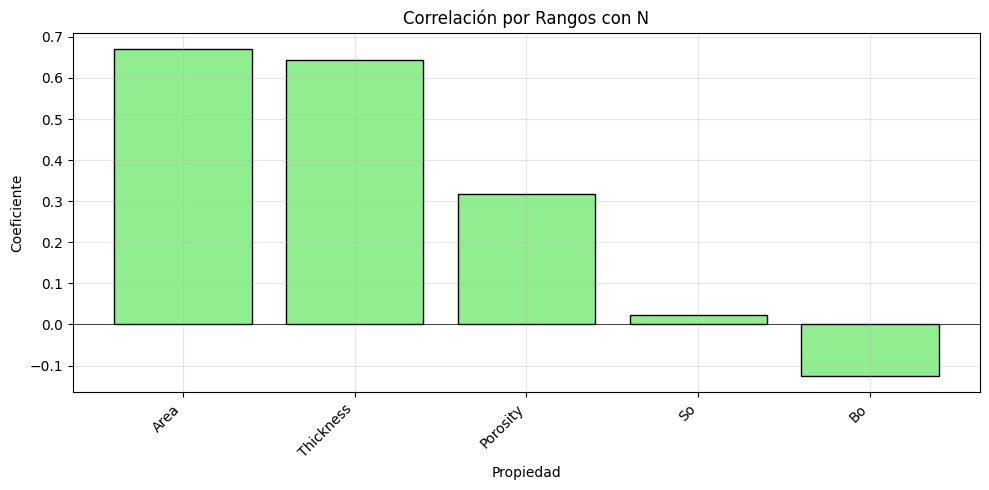

In [ ]:
# COVARIANZA POR PARES
cov = {k: np.cov(v, Y, ddof=1)[0,1] for k, v in X.items()}
df_cov = pd.DataFrame({'Propiedad': list(cov.keys()), 'Covarianza': list(cov.values())})
df_cov = df_cov.sort_values('Covarianza', ascending=False).reset_index(drop=True)
print("\n COVARIANZA POR PARES CON N:")
print(df_cov.to_string(index=False))

plt.figure(figsize=(10,5))
plt.bar(df_cov['Propiedad'], df_cov['Covarianza'], color='steelblue', edgecolor='black')
plt.title('Covarianza por Pares con N (MMSTB)'); plt.xlabel('Propiedad'); plt.ylabel('Covarianza')
plt.xticks(rotation=45, ha='right'); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

# CORRELACIÓN POR PARES
pares = {k: stats.pearsonr(v, Y)[0] for k, v in X.items()}
df_p = pd.DataFrame({'Propiedad': list(pares.keys()), 'Correlación por pares': list(pares.values())})
df_p = df_p.sort_values('Correlación por pares', ascending=False).reset_index(drop=True)
print("\n CORRELACIÓN POR PARES CON N:")
print(df_p.to_string(index=False))

plt.figure(figsize=(10,5))
plt.bar(df_p['Propiedad'], df_p['Correlación por pares'], color='coral', edgecolor='black')
plt.title('Correlación por Pares con N'); plt.xlabel('Propiedad'); plt.ylabel('Coeficiente')
plt.xticks(rotation=45, ha='right'); plt.axhline(0, color='black', lw=0.5)
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

# CORRELACIÓN POR RANGOS
rangos = {k: stats.spearmanr(v, Y)[0] for k, v in X.items()}
df_s = pd.DataFrame({'Propiedad': list(rangos.keys()), 'Correlación por rangos': list(rangos.values())})
df_s = df_s.sort_values('Correlación por rangos', ascending=False).reset_index(drop=True)
print("\n CORRELACIÓN POR RANGOS CON N:")
print(df_s.to_string(index=False))

plt.figure(figsize=(10,5))
plt.bar(df_s['Propiedad'], df_s['Correlación por rangos'], color='lightgreen', edgecolor='black')
plt.title('Correlación por Rangos con N'); plt.xlabel('Propiedad'); plt.ylabel('Coeficiente')
plt.xticks(rotation=45, ha='right'); plt.axhline(0, color='black', lw=0.5)
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

2.2 desarrollo

Para la última parte vamos a realizar una tabla y una gráfica comparativa de los 3 métodos utilizados

TABLA COMPARATIVA:
   Propiedad  Covarianza  Correlación por pares  Correlación por rangos  Rank_Cov  Rank_Pares  Rank_Rangos  Rank_Prom
1       Area  11614.2156                 0.6968                  0.6699         1           1            1        1.0
2  Thickness    661.8378                 0.5317                  0.6430         2           2            2        2.0
3   Porosity      0.6915                 0.3301                  0.3175         3           3            3        3.0
4         So      0.2730                 0.0613                  0.0240         4           4            4        4.0
5         Bo     -0.7284                -0.1259                 -0.1257         5           5            5        5.0


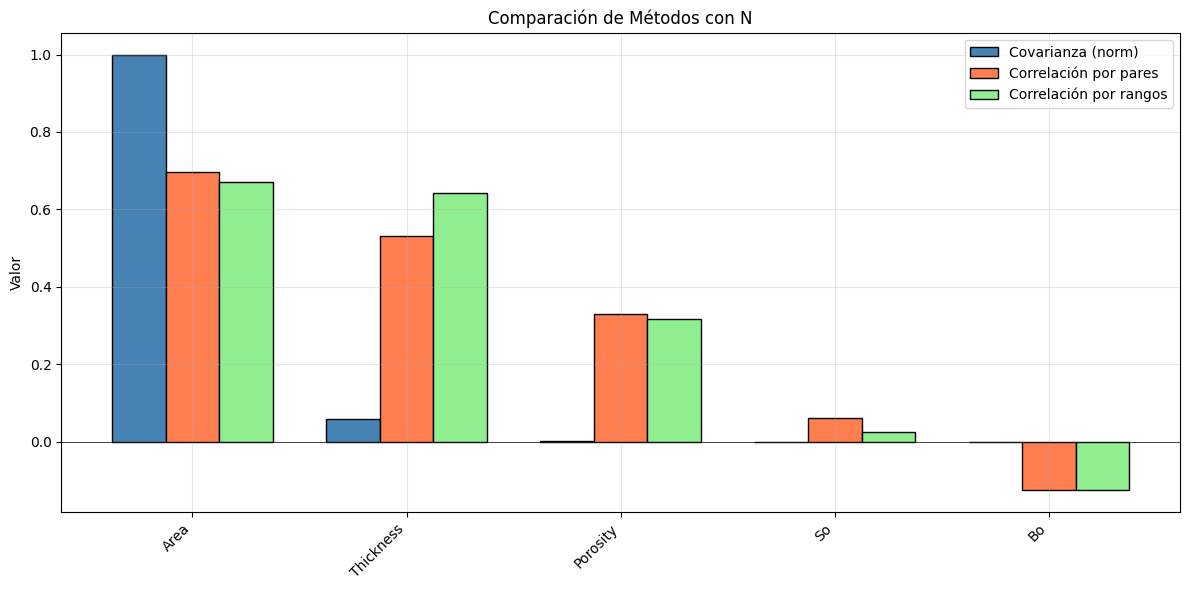


 La propiedad con mayor asociación con N es: Area


In [ ]:
# TABLA COMPARATIVA
tabla = pd.DataFrame({
    'Propiedad': list(X.keys()),
    'Covarianza': [cov[k] for k in X],
    'Correlación por pares': [pares[k] for k in X],
    'Correlación por rangos': [rangos[k] for k in X]
})
tabla['Rank_Cov'] = tabla['Covarianza'].rank(ascending=False).astype(int)
tabla['Rank_Pares'] = tabla['Correlación por pares'].rank(ascending=False).astype(int)
tabla['Rank_Rangos'] = tabla['Correlación por rangos'].rank(ascending=False).astype(int)
tabla['Rank_Prom'] = ((tabla['Rank_Cov'] + tabla['Rank_Pares'] + tabla['Rank_Rangos'])/3).round(2)
tabla = tabla.sort_values('Rank_Prom').reset_index(drop=True)
tabla.index += 1

print("TABLA COMPARATIVA:")
print(tabla.round(4).to_string())

# GRÁFICA COMPARATIVA
fig, ax = plt.subplots(figsize=(12,6))
x = np.arange(len(X)); w = 0.25
ax.bar(x-w, tabla['Covarianza']/tabla['Covarianza'].max(), w, label='Covarianza (norm)', color='steelblue', edgecolor='black')
ax.bar(x, tabla['Correlación por pares'], w, label='Correlación por pares', color='coral', edgecolor='black')
ax.bar(x+w, tabla['Correlación por rangos'], w, label='Correlación por rangos', color='lightgreen', edgecolor='black')
ax.set_xticks(x); ax.set_xticklabels(tabla['Propiedad'], rotation=45, ha='right')
ax.set_title('Comparación de Métodos con N'); ax.set_ylabel('Valor')
ax.axhline(0, color='black', lw=0.5); ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

print(f"\n La propiedad con mayor asociación con N es: {tabla.iloc[0]['Propiedad']}")

3.0 conclusión

El objetivo de identificar y ordenar las propiedades del yacimiento de acuerdo con su grado de asociación con el volumen original de aceite nos da como resultado después del análisis comparativo de los métodos utilizados que la variable con mayor asociación al volúmen original de aceite es el área en este caso en particular, seguido del espesor de la roca.

4.0 referencias

MoisesVL. (s/fb). Special topics/notes at main · Moises13r/PetroleumEng.

MoisesVL. (s/f-a). Special topics/data/OOIP.Csv at main · Moises13r/PetroleumEng.